# 1. Import thư viện, đọc Train và Validation

In [1]:
from pathlib import Path
import inspect
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_fscore_support,
    confusion_matrix,
)

EXPERIMENT_ID = "E11"
COMPARE_ID = "E10"
TARGET = "Attack_type"
RANDOM_STATE = 42
N_SPLITS = 3

CURRENT = Path.cwd().resolve()
ROOT = next(
    (
        parent
        for parent in [CURRENT, *CURRENT.parents]
        if (parent / "project").is_dir()
        and (parent / "splitted data").is_dir()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục sample_project có project và splitted data."
    )

DATA_DIR = ROOT / "splitted data"
TRAIN_PATH = DATA_DIR / "train.csv"
VALID_PATH = DATA_DIR / "validation.csv"
for data_path in (TRAIN_PATH, VALID_PATH):
    if not data_path.is_file():
        raise FileNotFoundError(data_path)

train_df = pd.read_csv(TRAIN_PATH)
valid_df = pd.read_csv(VALID_PATH)
print("=== THỰC NGHIỆM E11 ===")
print("MLP không sử dụng Scaler")
print("Train:", train_df.shape)
print("Validation:", valid_df.shape)

display(train_df.head(3))


=== THỰC NGHIỆM E11 ===
MLP không sử dụng Scaler
Train: (82536, 83)
Validation: (17686, 83)


,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,64177,46532,udp,-,0.000000,1,0,1,0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,NMAP_UDP_SCAN
1,20209,21,tcp,-,0.000005,1,1,1,0,199728.761905,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping
2,3694,21,tcp,-,0.000005,1,1,1,0,199728.761905,...,0.0,0.0,0.0,0.0,0.0,0.0,64,0,64,DOS_SYN_Hping


# 2. Xây dựng Pipeline MLP không dùng Scaler

In [2]:
# ========================================
# 1. TÁCH ĐẶC TRƯNG VÀ NHÃN
# ========================================

DROP_COLS = [
    TARGET,
    "Unnamed: 0",
    "group_id"
]

CATEGORICAL_FEATURES = [
    "proto",
    "service"
]

if (
    TARGET not in train_df.columns
    or TARGET not in valid_df.columns
):
    raise ValueError(
        f"Thiếu cột nhãn {TARGET}"
    )

if (
    train_df[TARGET].isna().any()
    or valid_df[TARGET].isna().any()
):
    raise ValueError("Nhãn có giá trị thiếu")

X = train_df.drop(
    columns=DROP_COLS,
    errors="ignore"
).copy()

y = train_df[TARGET].astype(str).copy()

X_valid = valid_df.drop(
    columns=DROP_COLS,
    errors="ignore"
).copy()

y_valid = valid_df[TARGET].astype(str).copy()

# Đồng bộ các cột giữa Train và Validation
if set(X.columns) != set(X_valid.columns):
    raise ValueError(
        "Train và Validation không có cùng tập đặc trưng"
    )

X_valid = X_valid[X.columns]

# ========================================
# 2. PHÂN LOẠI ĐẶC TRƯNG
# ========================================

missing_categories = [
    c for c in CATEGORICAL_FEATURES
    if c not in X.columns
]

if missing_categories:
    raise ValueError(
        f"Thiếu cột categorical: {missing_categories}"
    )

NUMERIC_FEATURES = X.select_dtypes(
    include=np.number
).columns.tolist()

unknown_features = sorted(
    set(X.columns)
    - set(NUMERIC_FEATURES)
    - set(CATEGORICAL_FEATURES)
)

if unknown_features:
    raise ValueError(
        f"Các cột chưa được xử lý: {unknown_features}"
    )

# ========================================
# 3. KIỂM TRA DỮ LIỆU
# ========================================

if X.isna().any().any() or X_valid.isna().any().any():
    raise ValueError(
        "Dữ liệu có NaN. Cần kiểm tra các tập đã chia sẵn."
    )

if not np.isfinite(
    X[NUMERIC_FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError("Train có giá trị vô hạn")

if not np.isfinite(
    X_valid[NUMERIC_FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError("Validation có giá trị vô hạn")

LABELS = sorted(y.unique().tolist())

if not set(y_valid.unique()).issubset(set(LABELS)):
    raise ValueError(
        "Validation có nhãn không tồn tại trong Train"
    )

if y.value_counts().min() < N_SPLITS:
    raise ValueError(
        "Mỗi lớp cần ít nhất 3 mẫu để chia 3-fold"
    )

# ========================================
# 4. HÀM TẠO PIPELINE E11
# ========================================

def make_e11_pipeline():

    # Tương thích nhiều phiên bản sklearn
    ohe_args = {
        "handle_unknown": "ignore"
    }

    if "sparse_output" in inspect.signature(
        OneHotEncoder
    ).parameters:
        ohe_args["sparse_output"] = False
    else:
        ohe_args["sparse"] = False

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                "passthrough",
                NUMERIC_FEATURES
            ),
            (
                "categorical",
                OneHotEncoder(**ohe_args),
                CATEGORICAL_FEATURES
            )
        ],
        remainder="drop",
        sparse_threshold=0
    )

    mlp = MLPClassifier(
        hidden_layer_sizes=(64,),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        batch_size=512,
        max_iter=60,
        n_iter_no_change=8,
        early_stopping=False,
        random_state=RANDOM_STATE,
        verbose=False
    )

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", mlp)
    ])

# ========================================
# 5. HÀM ĐÁNH GIÁ MÔ HÌNH
# ========================================

METRICS = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "macro_precision",
    "macro_recall"
]

def evaluate(y_true, y_pred):

    return {
        "accuracy": accuracy_score(
            y_true, y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="weighted",
            zero_division=0
        ),

        "macro_precision": precision_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),

        "macro_recall": recall_score(
            y_true,
            y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        )
    }

# ========================================
# 6. KIỂM TRA PIPELINE
# ========================================

print("=== THÔNG TIN E11 ===")
print("Số mẫu Train:", len(X))
print("Số mẫu Validation:", len(X_valid))
print("Số lớp:", len(LABELS))
print("Số đặc trưng số:", len(NUMERIC_FEATURES))
print("Đặc trưng phân loại:", CATEGORICAL_FEATURES)

print("\n=== PIPELINE E11 ===")
print(make_e11_pipeline())

print("\n=== PHÂN BỐ NHÃN TRAIN ===")
display(y.value_counts())

=== THÔNG TIN E11 ===
Số mẫu Train: 82536
Số mẫu Validation: 17686
Số lớp: 12
Số đặc trưng số: 80
Đặc trưng phân loại: ['proto', 'service']

=== PIPELINE E11 ===
Pipeline(steps=[('preprocess',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('numeric', 'passthrough',
                                                  ['id.orig_p', 'id.resp_p',
                                                   'flow_duration',
                                                   'fwd_pkts_tot',
                                                   'bwd_pkts_tot',
                                                   'fwd_data_pkts_tot',
                                                   'bwd_data_pkts_tot',
                                                   'fwd_pkts_per_sec',
                                                   'bwd_pkts_per_sec',
                                                   'flow_pkts_per_sec',
                                       

Attack_type
DOS_SYN_Hping                 63062
Thing_Speak                    5355
ARP_poisioning                 5334
MQTT_Publish                   2899
NMAP_UDP_SCAN                  1807
NMAP_XMAS_TREE_SCAN            1407
NMAP_OS_DETECTION              1400
NMAP_TCP_scan                   701
DDOS_Slowloris                  373
Wipro_bulb                      153
Metasploit_Brute_Force_SSH       25
NMAP_FIN_SCAN                    20
Name: count, dtype: int64

### Tiền xử lý thực nghiệm E11

- Đặc trưng số được giữ nguyên, không chuẩn hóa.
- `proto` và `service` được OneHotEncoder mã hóa trong Pipeline.
- Bộ mã hóa được fit riêng theo từng fold Cross-Validation.


# 3. Huấn luyện 3-ford Cross-Validation

In [3]:
# ========================================
# 3-FOLD CROSS-VALIDATION
# ========================================

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_rows = []
per_class_rows = []
loss_curves = {}

for fold, (fit_idx, cv_idx) in enumerate(
    cv.split(X, y),
    start=1
):

    print("\n" + "=" * 55)
    print(f"E11 - FOLD {fold}/{N_SPLITS}")
    print("=" * 55)

    # Dữ liệu huấn luyện của fold
    X_fit = X.iloc[fit_idx]
    y_fit = y.iloc[fit_idx]

    # Dữ liệu kiểm định của fold
    X_cv = X.iloc[cv_idx]
    y_cv = y.iloc[cv_idx]

    # Khởi tạo mô hình mới
    fold_pipeline = make_e11_pipeline()

    start_time = time.perf_counter()

    # Huấn luyện
    fold_pipeline.fit(X_fit, y_fit)

    elapsed = time.perf_counter() - start_time

    # Dự đoán
    pred_cv = fold_pipeline.predict(X_cv)
    pred_train = fold_pipeline.predict(X_fit)

    # Tính các chỉ số
    cv_scores = evaluate(y_cv, pred_cv)
    train_scores = evaluate(y_fit, pred_train)

    trained_mlp = fold_pipeline.named_steps["model"]

    # Lưu Training Loss
    loss_curves[fold] = list(
        trained_mlp.loss_curve_
    )

    # Lưu kết quả fold
    fold_rows.append({
        "fold": fold,
        "n_train": len(X_fit),
        "n_cv": len(X_cv),
        "epochs": int(trained_mlp.n_iter_),
        "training_time_sec": float(elapsed),
        "final_train_loss": float(trained_mlp.loss_),

        **cv_scores,

        **{
            f"train_{m}": train_scores[m]
            for m in METRICS
        }
    })

    # Tính kết quả từng lớp
    p, r, f, support = (
        precision_recall_fscore_support(
            y_cv,
            pred_cv,
            labels=LABELS,
            zero_division=0
        )
    )

    for label, precision, recall, f1_value, n in zip(
        LABELS,
        p,
        r,
        f,
        support
    ):

        per_class_rows.append({
            "fold": fold,
            "class": label,
            "precision": float(precision),
            "recall": float(recall),
            "f1": float(f1_value),
            "support": int(n)
        })

    print("Số mẫu Train:", len(X_fit))
    print("Số mẫu CV:", len(X_cv))
    print("Số epoch:", trained_mlp.n_iter_)
    print(f"Thời gian: {elapsed:.2f} giây")

    print("\n=== CHỈ SỐ ĐÁNH GIÁ ===")

    for metric in METRICS:
        print(
            f"{metric:18s}: {cv_scores[metric]:.6f}"
        )

# ========================================
# TỔNG HỢP KẾT QUẢ
# ========================================

cv_results = pd.DataFrame(fold_rows)

cv_per_class = pd.DataFrame(per_class_rows)

cv_summary = pd.DataFrame({
    "metric": METRICS,

    "mean": [
        float(cv_results[m].mean())
        for m in METRICS
    ],

    "std": [
        float(cv_results[m].std(ddof=1))
        for m in METRICS
    ]
})

cv_per_class_summary = (
    cv_per_class
    .groupby("class", as_index=False)
    .agg(
        precision_mean=("precision", "mean"),
        recall_mean=("recall", "mean"),
        f1_mean=("f1", "mean"),
        support_total=("support", "sum")
    )
    .sort_values("f1_mean")
)

print("\n=== KẾT QUẢ 3 FOLD ===")

display(
    cv_results[
        [
            "fold",
            *METRICS,
            "epochs",
            "training_time_sec"
        ]
    ].round(6)
)

print("\n=== TRUNG BÌNH 3 FOLD ===")

display(cv_summary.round(6))

print("\n=== CÁC LỚP CÓ F1 THẤP ===")

display(
    cv_per_class_summary.head(5).round(6)
)

# ========================================
# LƯU KẾT QUẢ VÀO FOLDER E11
# ========================================





print("\nĐã lưu kết quả 3-fold CV.")


E11 - FOLD 1/3
Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 41
Thời gian: 15.02 giây

=== CHỈ SỐ ĐÁNH GIÁ ===
accuracy          : 0.971940
macro_f1          : 0.697902
weighted_f1       : 0.971742
macro_precision   : 0.695149
macro_recall      : 0.708311

E11 - FOLD 2/3
Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 56
Thời gian: 18.36 giây

=== CHỈ SỐ ĐÁNH GIÁ ===
accuracy          : 0.947768
macro_f1          : 0.700529
weighted_f1       : 0.944636
macro_precision   : 0.720747
macro_recall      : 0.795420

E11 - FOLD 3/3
Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 31
Thời gian: 10.80 giây

=== CHỈ SỐ ĐÁNH GIÁ ===
accuracy          : 0.961835
macro_f1          : 0.718145
weighted_f1       : 0.960202
macro_precision   : 0.739939
macro_recall      : 0.729083

=== KẾT QUẢ 3 FOLD ===


,fold,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,epochs,training_time_sec
0,1,0.971940,0.697902,0.971742,0.695149,0.708311,41,15.024095
1,2,0.947768,0.700529,0.944636,0.720747,0.795420,56,18.361136
2,3,0.961835,0.718145,0.960202,0.739939,0.729083,31,10.799234



=== TRUNG BÌNH 3 FOLD ===


,metric,mean,std
0,accuracy,0.960514,0.012140
1,macro_f1,0.705525,0.011008
2,weighted_f1,0.958860,0.013603
3,macro_precision,0.718611,0.022471
4,macro_recall,0.744271,0.045498



=== CÁC LỚP CÓ F1 THẤP ===


,class,precision_mean,recall_mean,f1_mean,support_total
4,Metasploit_Brute_Force_SSH,0.053333,0.166667,0.080808,25
11,Wipro_bulb,0.472088,0.568627,0.433902,153
9,NMAP_XMAS_TREE_SCAN,0.591607,0.542999,0.478646,1407
5,NMAP_FIN_SCAN,0.507937,0.571429,0.535714,20
6,NMAP_OS_DETECTION,0.616505,0.608822,0.563849,1400



Đã lưu kết quả 3-fold CV.



### Huấn luyện mô hình bằng 3-fold Cross-Validation

**Quy trình:**
- Sử dụng StratifiedKFold với 3 fold.
- Mỗi fold khởi tạo một Pipeline MLP mới.

**Các chỉ số:**
- Accuracy.
- Macro-F1.
- Weighted-F1.
- Macro-Precision.
- Macro-Recall.

**Thông tin bổ sung:**
- Thời gian huấn luyện.
- Số epoch.
- Training Loss.
- F1-score của từng lớp.


# 4. Huấn luyện toàn bộ Train và đánh giá Validation

In [4]:
# ========================================
# HUẤN LUYỆN TRÊN TOÀN BỘ TRAIN
# ========================================

final_model = make_e11_pipeline()

start_time = time.perf_counter()

final_model.fit(X, y)

full_train_time = (
    time.perf_counter() - start_time
)

# Dự đoán
pred_train = final_model.predict(X)
pred_valid = final_model.predict(X_valid)

# Tính chỉ số
train_scores = evaluate(y, pred_train)
valid_scores = evaluate(y_valid, pred_valid)

final_mlp = final_model.named_steps["model"]

print("=== HUẤN LUYỆN FULL TRAIN ===")
print("Số mẫu:", len(X))
print("Số epoch:", final_mlp.n_iter_)
print(f"Thời gian: {full_train_time:.2f} giây")

# ========================================
# BẢNG CHỈ SỐ TRAIN VÀ VALIDATION
# ========================================

validation_metrics = pd.DataFrame({
    "metric": METRICS,

    "train": [
        train_scores[m]
        for m in METRICS
    ],

    "validation": [
        valid_scores[m]
        for m in METRICS
    ]
})

validation_metrics["train_valid_gap"] = (
    validation_metrics["train"]
    - validation_metrics["validation"]
)

print("\n=== TRAIN / VALIDATION ===")

display(validation_metrics.round(6))

# ========================================
# ĐÁNH GIÁ TỪNG LỚP
# ========================================

p, r, f, support = (
    precision_recall_fscore_support(
        y_valid,
        pred_valid,
        labels=LABELS,
        zero_division=0
    )
)

validation_per_class = pd.DataFrame({
    "class": LABELS,
    "precision": p,
    "recall": r,
    "f1": f,
    "support": support
})

print("\n=== F1-SCORE TỪNG LỚP ===")

display(
    validation_per_class
    .sort_values("f1")
    .round(6)
)

# ========================================
# CONFUSION MATRIX
# ========================================

cm = confusion_matrix(
    y_valid,
    pred_valid,
    labels=LABELS
)

cm_df = pd.DataFrame(
    cm,
    index=LABELS,
    columns=LABELS
)

# ========================================
# TỔNG HỢP CV VÀ VALIDATION CỦA E11
# ========================================

cv_vs_validation = (
    cv_summary[
        ["metric", "mean", "std"]
    ]
    .merge(
        validation_metrics[
            ["metric", "validation"]
        ],
        on="metric"
    )
)

cv_vs_validation["validation_minus_cv_mean"] = (
    cv_vs_validation["validation"]
    - cv_vs_validation["mean"]
)

print("\n=== CV / VALIDATION CỦA E11 ===")

display(cv_vs_validation.round(6))

# ========================================
# LƯU CSV
# ========================================





print("\nĐã lưu kết quả Validation.")

=== HUẤN LUYỆN FULL TRAIN ===
Số mẫu: 82536
Số epoch: 35
Thời gian: 18.53 giây

=== TRAIN / VALIDATION ===


,metric,train,validation,train_valid_gap
0,accuracy,0.951124,0.949791,0.001334
1,macro_f1,0.674377,0.634353,0.040024
2,weighted_f1,0.947563,0.946337,0.001226
3,macro_precision,0.729564,0.667884,0.061680
4,macro_recall,0.679400,0.648934,0.030467



=== F1-SCORE TỪNG LỚP ===


,class,precision,recall,f1,support
5,NMAP_FIN_SCAN,0.000000,0.000000,0.000000,4
4,Metasploit_Brute_Force_SSH,0.000000,0.000000,0.000000,5
9,NMAP_XMAS_TREE_SCAN,0.673469,0.109272,0.188034,302
11,Wipro_bulb,0.486486,0.545455,0.514286,33
6,NMAP_OS_DETECTION,0.518182,0.950000,0.670588,300
10,Thing_Speak,0.862928,0.724499,0.787678,1147
0,ARP_poisioning,0.720578,0.873141,0.789557,1143
1,DDOS_Slowloris,0.871429,0.762500,0.813333,80
8,NMAP_UDP_SCAN,0.930836,0.834625,0.880109,387
3,MQTT_Publish,0.950845,0.996779,0.973270,621



=== CV / VALIDATION CỦA E11 ===


,metric,mean,std,validation,validation_minus_cv_mean
0,accuracy,0.960514,0.012140,0.949791,-0.010723
1,macro_f1,0.705525,0.011008,0.634353,-0.071172
2,weighted_f1,0.958860,0.013603,0.946337,-0.012523
3,macro_precision,0.718611,0.022471,0.667884,-0.050728
4,macro_recall,0.744271,0.045498,0.648934,-0.095338



Đã lưu kết quả Validation.



### Huấn luyện toàn bộ Train và đánh giá Validation

**Quy trình:**
- Khởi tạo lại mô hình MLP E11.
- Huấn luyện trên toàn bộ Train.
- Dự đoán trên Validation.
- Tính 5 chỉ số đánh giá.
- Đánh giá Precision, Recall và F1-score của từng lớp.

**Mục tiêu:**

Quan sát khả năng phân loại và mức độ tổng quát hóa của mô hình MLP khi không sử dụng Scaler.


# 5. Vẽ biểu đồ kết quả

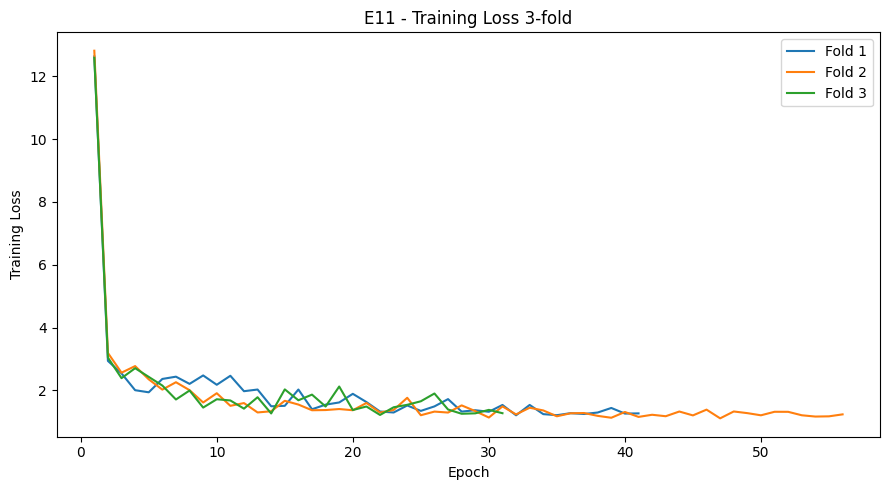

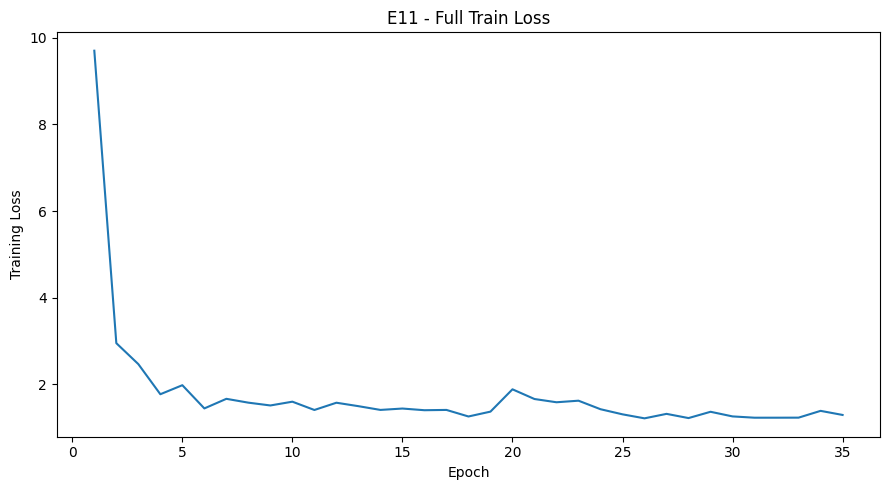

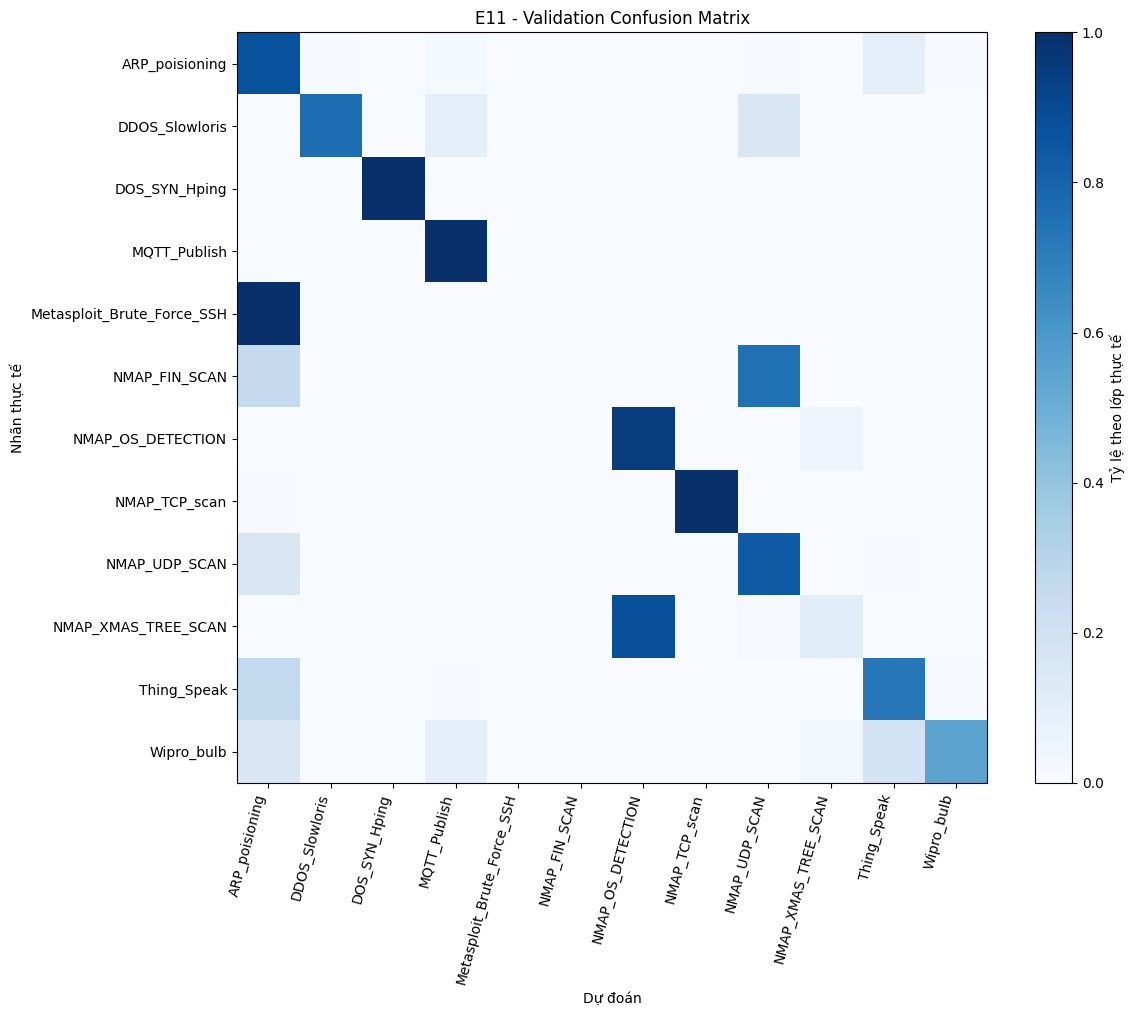

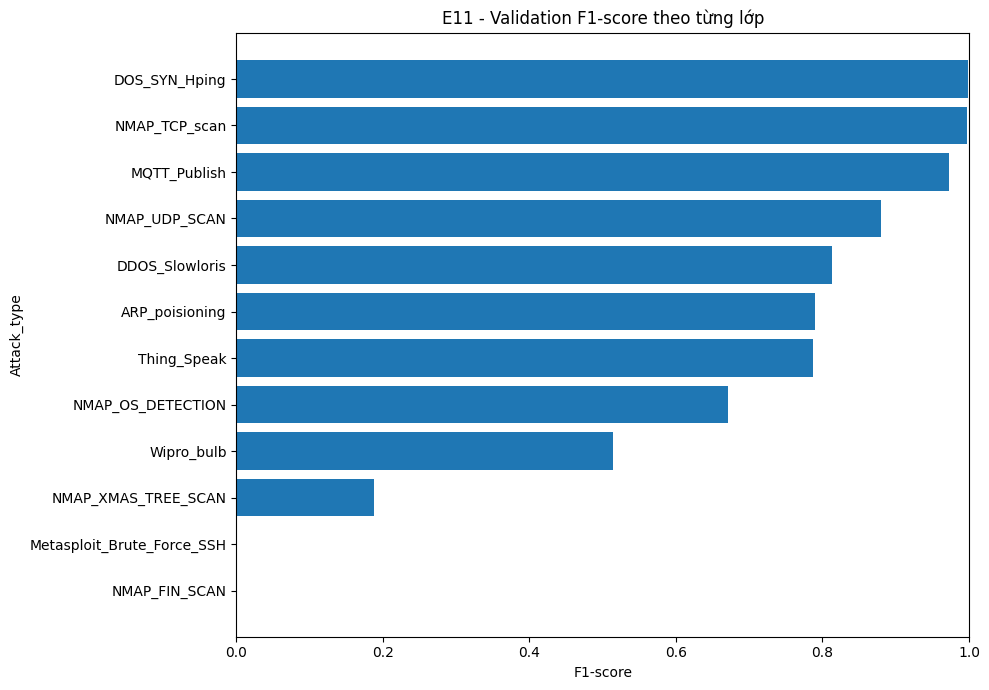

In [5]:
# ========================================
# 5.1. TRAINING LOSS 3 FOLD
# ========================================

fig, ax = plt.subplots(figsize=(9, 5))

for fold, losses in loss_curves.items():

    ax.plot(
        range(1, len(losses) + 1),
        losses,
        label=f"Fold {fold}"
    )

ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("E11 - Training Loss 3-fold")

ax.legend()
fig.tight_layout()


plt.show()


# ========================================
# 5.2. TRAINING LOSS FULL TRAIN
# ========================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    range(1, len(final_mlp.loss_curve_) + 1),
    final_mlp.loss_curve_
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("E11 - Full Train Loss")

fig.tight_layout()


plt.show()


# ========================================
# 5.3. CONFUSION MATRIX VALIDATION
# ========================================

row_totals = cm.sum(
    axis=1,
    keepdims=True
)

cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    cm_normalized,
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(LABELS)))
ax.set_yticks(range(len(LABELS)))

ax.set_xticklabels(
    LABELS,
    rotation=75,
    ha="right"
)

ax.set_yticklabels(LABELS)

ax.set_xlabel("Dự đoán")
ax.set_ylabel("Nhãn thực tế")

ax.set_title(
    "E11 - Validation Confusion Matrix"
)

fig.colorbar(
    im,
    ax=ax,
    label="Tỷ lệ theo lớp thực tế"
)

fig.tight_layout()


plt.show()


# ========================================
# 5.4. F1-SCORE THEO TỪNG LỚP
# ========================================

f1_plot = (
    validation_per_class
    .sort_values("f1")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    f1_plot["class"],
    f1_plot["f1"]
)

ax.set_xlim(0, 1)

ax.set_xlabel("F1-score")
ax.set_ylabel("Attack_type")
ax.set_title(
    "E11 - Validation F1-score theo từng lớp"
)

fig.tight_layout()


plt.show()





### Trực quan hóa kết quả thực nghiệm E11

**Các biểu đồ:**
- Training Loss của 3 fold.
- Training Loss trên toàn bộ Train.
- Confusion Matrix trên Validation.
- F1-score theo từng lớp trên Validation.

**Ý nghĩa:**

Training Loss giúp theo dõi quá trình tối ưu của MLP.

Confusion Matrix giúp quan sát các trường hợp phân loại chính xác và nhầm lẫn giữa các nhãn.

Biểu đồ F1-score theo từng lớp giúp xác định những lớp mà mô hình dự đoán chưa tốt.


## 6. Tổng hợp kết quả trong notebook

Các chỉ số được hiển thị trực tiếp; notebook không xuất file vào `result`.


In [6]:
print("Kết quả được giữ trong notebook; không ghi file vào result.")
display(cv_summary)
display(validation_metrics)
display(cv_vs_validation)


Kết quả được giữ trong notebook; không ghi file vào result.


,metric,mean,std
0,accuracy,0.960514,0.012140
1,macro_f1,0.705525,0.011008
2,weighted_f1,0.958860,0.013603
3,macro_precision,0.718611,0.022471
4,macro_recall,0.744271,0.045498


,metric,train,validation,train_valid_gap
0,accuracy,0.951124,0.949791,0.001334
1,macro_f1,0.674377,0.634353,0.040024
2,weighted_f1,0.947563,0.946337,0.001226
3,macro_precision,0.729564,0.667884,0.061680
4,macro_recall,0.679400,0.648934,0.030467


,metric,mean,std,validation,validation_minus_cv_mean
0,accuracy,0.960514,0.012140,0.949791,-0.010723
1,macro_f1,0.705525,0.011008,0.634353,-0.071172
2,weighted_f1,0.958860,0.013603,0.946337,-0.012523
3,macro_precision,0.718611,0.022471,0.667884,-0.050728
4,macro_recall,0.744271,0.045498,0.648934,-0.095338
